# Detecção de anomalias em transações de cartão

**Caio Siqueira · Projeto DIO · Bradesco Agentes de IA do Zero à Prática**

O objetivo é selecionar transações para revisão com alta cobertura de fraudes e medir o custo em falsos alertas. A base pública **Credit Card Fraud Detection** contém transações reais anonimizadas, coletadas na Europa em dois dias de setembro de 2013. `Class=1` é fraude e `Class=0` é transação legítima. Com apenas 0,17% de fraudes, um classificador que libera tudo tem cerca de 99,83% de acurácia e recall zero.

**Protocolo.** Divisão estratificada 60% treino, 20% validação e 20% teste. O treino ajusta os modelos. A validação escolhe limiares e a configuração principal. O teste mede o resultado final com essas decisões congeladas. A meta de precisão de 60% é uma escolha didática para controlar o volume de falsos positivos.

[Base original da ULB / Worldline no Kaggle](https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud) · [Espelho Zenodo](https://zenodo.org/records/7395559)

In [1]:
import os
from pathlib import Path
from zipfile import BadZipFile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xgboost as xgb
from IPython.display import display
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay, PrecisionRecallDisplay, RocCurveDisplay,
    average_precision_score, classification_report, confusion_matrix,
    precision_recall_curve, precision_recall_fscore_support, roc_auc_score,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

SEED = 42
THREADS = 4
MIN_PRECISION = 0.60
URL = "https://www.kaggle.com/api/v1/datasets/download/mlg-ulb/creditcardfraud"
MIRROR = "https://zenodo.org/records/7395559/files/creditcard.csv?download=1"
plt.rcParams.update({"figure.dpi": 90, "axes.spines.top": False, "axes.spines.right": False})

## 1. Coleta e exploração

Por padrão, o notebook baixa o ZIP público. Se a fonte principal falhar, tenta o CSV equivalente do Zenodo. A variável opcional `CREDITCARD_CSV` aceita uma cópia local do mesmo arquivo para reexecutar offline. `V1` a `V28` são componentes anonimizados por PCA. `Time` mede segundos desde a primeira transação da base e `Amount` é o valor original.

In [2]:
local_csv = os.environ.get("CREDITCARD_CSV")
if local_csv:
    dados = pd.read_csv(Path(local_csv))
else:
    try:
        dados = pd.read_csv(URL, compression="zip")
    except (OSError, ValueError, BadZipFile):
        dados = pd.read_csv(MIRROR)

colunas = {"Time", "Amount", "Class"} | {f"V{i}" for i in range(1, 29)}
assert set(dados.columns) == colunas, "O esquema difere da base esperada."
assert dados.shape == (284_807, 31) and int(dados["Class"].sum()) == 492
assert set(dados["Class"].unique()) == {0, 1}
assert not dados.isna().any().any() and dados["Amount"].ge(0).all()

contagem = dados["Class"].value_counts().sort_index()
resumo = pd.DataFrame({"transações": contagem, "proporção (%)": 100 * contagem / len(dados)})
resumo.index = ["Legítima (0)", "Fraude (1)"]
display(resumo.round(4))
print(f"Linhas integralmente repetidas após a primeira ocorrência: {dados.duplicated().sum():,}")

,transações,proporção (%)
Legítima (0),284315,99.8273
Fraude (1),492,0.1727


Linhas integralmente repetidas após a primeira ocorrência: 1,081


## 2. Preparação e separação

Cria-se `LogAmount = log(1 + Amount)` e usa-se essa variável no lugar de `Amount`. O alvo fica fora das entradas. `StandardScaler` é ajustado apenas no treino, dentro dos pipelines de regressão logística. Os modelos de árvore recebem as mesmas variáveis sem escala.

As duplicatas integrais são removidas antes da divisão para impedir que uma cópia idêntica de uma transação apareça em mais de um conjunto. Como a base não fornece identificador por transação, essa decisão pode também remover compras distintas com os mesmos campos. A divisão aleatória estratificada mede desempenho retrospectivo e deve ser complementada por uma divisão temporal em uma aplicação real.

In [3]:
dados = dados.drop_duplicates().copy()
X = dados.drop(columns=["Class", "Amount"]).assign(LogAmount=np.log1p(dados["Amount"]))
y = dados["Class"].astype(int)

X_treino, X_restante, y_treino, y_restante = train_test_split(
    X, y, test_size=0.40, stratify=y, random_state=SEED
)
X_val, X_teste, y_val, y_teste = train_test_split(
    X_restante, y_restante, test_size=0.50, stratify=y_restante, random_state=SEED
)
assert set(X_treino.index).isdisjoint(X_val.index)
assert set(X_treino.index).isdisjoint(X_teste.index)
assert set(X_val.index).isdisjoint(X_teste.index)

particoes = pd.DataFrame(
    [(nome, len(alvo), int(alvo.sum()), 100 * alvo.mean())
     for nome, alvo in [("Treino", y_treino), ("Validação", y_val), ("Teste", y_teste)]],
    columns=["partição", "linhas", "fraudes", "fraudes (%)"],
)
display(particoes.round(4))

,partição,linhas,fraudes,fraudes (%)
0,Treino,170235,284,0.1668
1,Validação,56745,94,0.1657
2,Teste,56746,95,0.1674


## 3. Modelos e desbalanceamento

A regressão logística sem pesos fornece o baseline. A versão ponderada e a Random Forest usam `class_weight="balanced"`. No XGBoost, `scale_pos_weight` é a razão entre legítimas e fraudes **somente no treino**. A experiência com subamostragem mantém todas as fraudes e sorteia dez transações legítimas por fraude, sem reposição e apenas no treino. Validação e teste preservam a prevalência natural.

In [4]:
peso_xgb = (len(y_treino) - y_treino.sum()) / y_treino.sum()
modelos = {
    "Logística baseline": make_pipeline(StandardScaler(), LogisticRegression(max_iter=500, random_state=SEED)),
    "Logística ponderada": make_pipeline(
        StandardScaler(), LogisticRegression(class_weight="balanced", max_iter=500, random_state=SEED)
    ),
    "Logística subamostrada": make_pipeline(StandardScaler(), LogisticRegression(max_iter=500, random_state=SEED)),
    "Random Forest ponderada": RandomForestClassifier(
        n_estimators=100, max_depth=14, min_samples_leaf=2, class_weight="balanced",
        max_features="sqrt", n_jobs=THREADS, random_state=SEED,
    ),
    "XGBoost ponderado": xgb.XGBClassifier(
        n_estimators=180, max_depth=4, learning_rate=0.08, min_child_weight=4,
        subsample=0.85, colsample_bytree=0.85, tree_method="hist",
        objective="binary:logistic", eval_metric="logloss", scale_pos_weight=float(peso_xgb),
        n_jobs=THREADS, random_state=SEED,
    ),
}

fraudes_treino = y_treino[y_treino.eq(1)]
legitimas_treino = y_treino[y_treino.eq(0)]
indices_sub = fraudes_treino.index.union(
    legitimas_treino.sample(n=min(len(legitimas_treino), 10 * len(fraudes_treino)),
                           random_state=SEED).index
)
scores_val = {}
for nome, modelo in modelos.items():
    indices = indices_sub if nome == "Logística subamostrada" else X_treino.index
    modelo.fit(X_treino.loc[indices], y_treino.loc[indices])
    scores_val[nome] = modelo.predict_proba(X_val)[:, 1]
    print(f"{nome}: {len(indices):,} transações usadas no treino")

Logística baseline: 170,235 transações usadas no treino
Logística ponderada: 170,235 transações usadas no treino
Logística subamostrada: 3,124 transações usadas no treino
Random Forest ponderada: 170,235 transações usadas no treino
XGBoost ponderado: 170,235 transações usadas no treino


## 4. Escolha de modelo e limiar na validação

Entre limiares com precisão de pelo menos 60%, maximiza-se o recall, depois o F1. O fallback, se nenhum limiar atingir a meta, é o maior F1 na validação. Entre modelos, têm preferência os que cumprem a meta. Os desempates usam recall, F1 e AP. Os escores podem mudar com pesos e amostragem, portanto o corte não deve ser interpretado como probabilidade calibrada de fraude.

In [5]:
def avaliar(alvo, scores, limiar):
    previsto = scores >= limiar
    precisao, recall, f1, _ = precision_recall_fscore_support(
        alvo, previsto, average="binary", zero_division=0
    )
    tn, fp, fn, tp = confusion_matrix(alvo, previsto, labels=[0, 1]).ravel()
    return {
        "limiar": limiar, "precisão": precisao, "recall": recall, "F1": f1,
        "AP": average_precision_score(alvo, scores), "ROC AUC": roc_auc_score(alvo, scores),
        "VP": int(tp), "FP": int(fp), "FN": int(fn), "VN": int(tn),
    }


def escolher_limiar(alvo, scores):
    precisao, recall, limiares = precision_recall_curve(alvo, scores)
    p, r = precisao[:-1], recall[:-1]  # O último ponto da curva não tem limiar.
    f1 = np.divide(2 * p * r, p + r, out=np.zeros_like(p), where=(p + r) > 0)
    viaveis = np.flatnonzero(p >= MIN_PRECISION)
    if viaveis.size:
        melhor = max(viaveis, key=lambda i: (r[i], f1[i], p[i], limiares[i]))
    else:
        melhor = max(range(len(limiares)), key=lambda i: (f1[i], r[i], p[i], limiares[i]))
    return float(limiares[melhor]), bool(viaveis.size)


limiares = {nome: escolher_limiar(y_val, scores) for nome, scores in scores_val.items()}
validacao = pd.DataFrame.from_dict(
    {nome: avaliar(y_val, scores, limiares[nome][0]) for nome, scores in scores_val.items()},
    orient="index",
)
validacao["meta atendida"] = [limiares[nome][1] for nome in validacao.index]
validacao = validacao.sort_values(["meta atendida", "recall", "F1", "AP"], ascending=False)
modelo_escolhido = validacao.index[0]
limiar_escolhido = limiares[modelo_escolhido][0]
display(validacao.round(4))
print(f"Seleção congelada antes do teste: {modelo_escolhido}, limiar {limiar_escolhido:.6f}.")

,limiar,precisão,recall,F1,AP,ROC AUC,VP,FP,FN,VN,meta atendida
Random Forest ponderada,0.2170,0.7917,0.8085,0.8000,0.7947,0.9421,76,20,18,56631,True
XGBoost ponderado,0.4883,0.6757,0.7979,0.7317,0.7850,0.9664,75,36,19,56615,True
Logística baseline,0.0229,0.6379,0.7872,0.7048,0.6980,0.9663,74,42,20,56609,True
Logística ponderada,0.9999,0.7526,0.7766,0.7644,0.6984,0.9616,73,24,21,56627,True
Logística subamostrada,0.7649,0.6186,0.7766,0.6887,0.6785,0.9674,73,45,21,56606,True


Seleção congelada antes do teste: Random Forest ponderada, limiar 0.217030.


## 5. Avaliação final no teste

**Recall** mede a fração de fraudes capturadas. **Precisão** mede a fração de alertas que realmente eram fraudes. **F1** sintetiza as duas. **AP** resume a curva de precisão e recall e deve ser comparada com a prevalência do teste. A curva ROC é complementar. Os mesmos escores são avaliados com corte 0,5 e com o corte escolhido na validação, sem reajustar o modelo.

In [6]:
scores_teste = {nome: modelo.predict_proba(X_teste)[:, 1] for nome, modelo in modelos.items()}
teste = pd.DataFrame.from_dict(
    {nome: avaliar(y_teste, scores, limiares[nome][0]) for nome, scores in scores_teste.items()},
    orient="index",
).loc[validacao.index]
padrao = pd.DataFrame.from_dict(
    {nome: avaliar(y_teste, scores, 0.5) for nome, scores in scores_teste.items()},
    orient="index",
).loc[validacao.index]
display(teste.round(4))
display(pd.concat(
    {"Corte 0,5": padrao[["precisão", "recall", "F1", "FP"]],
     "Corte validado": teste[["precisão", "recall", "F1", "FP"]]},
    axis=1,
).round(4))

predito = scores_teste[modelo_escolhido] >= limiar_escolhido
print(classification_report(y_teste, predito, labels=[0, 1],
                            target_names=["Legítima", "Fraude"], zero_division=0, digits=4))

,limiar,precisão,recall,F1,AP,ROC AUC,VP,FP,FN,VN
Random Forest ponderada,0.2170,0.7778,0.8105,0.7938,0.8424,0.9655,77,22,18,56629
XGBoost ponderado,0.4883,0.7273,0.8421,0.7805,0.8429,0.9767,80,30,15,56621
Logística baseline,0.0229,0.6471,0.8105,0.7196,0.7454,0.9642,77,42,18,56609
Logística ponderada,0.9999,0.7812,0.7895,0.7853,0.7253,0.9622,75,21,20,56630
Logística subamostrada,0.7649,0.6555,0.8211,0.7290,0.7192,0.9667,78,41,17,56610


Corte 0,5                  ... Corte validado            
                         precisão  recall      F1  ...         recall      F1  FP
Random Forest ponderada    0.9730  0.7579  0.8521  ...         0.8105  0.7938  22
XGBoost ponderado          0.7339  0.8421  0.7843  ...         0.8421  0.7805  30
Logística baseline         0.8788  0.6105  0.7205  ...         0.8105  0.7196  42
Logística ponderada        0.0594  0.9053  0.1115  ...         0.7895  0.7853  21
Logística subamostrada     0.4362  0.8632  0.5795  ...         0.8211  0.7290  41

[5 rows x 8 columns]

              precision    recall  f1-score   support

    Legítima     0.9997    0.9996    0.9996     56651
      Fraude     0.7778    0.8105    0.7938        95

    accuracy                         0.9993     56746
   macro avg     0.8887    0.9051    0.8967     56746
weighted avg     0.9993    0.9993    0.9993     56746



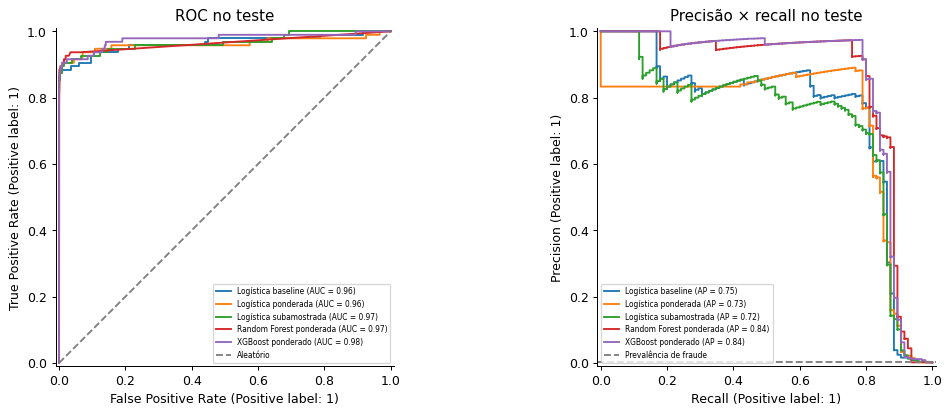

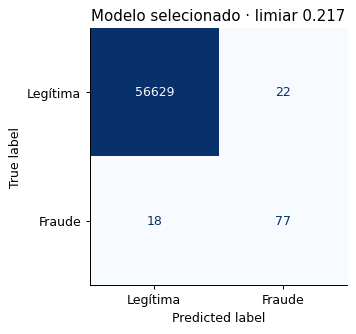

In [7]:
fig, eixos = plt.subplots(1, 2, figsize=(12, 4.5), layout="constrained")
for nome, scores in scores_teste.items():
    RocCurveDisplay.from_predictions(y_teste, scores, name=nome, ax=eixos[0])
    PrecisionRecallDisplay.from_predictions(y_teste, scores, name=nome, ax=eixos[1])
eixos[0].plot([0, 1], [0, 1], "--", color="gray", label="Aleatório")
eixos[0].set_title("ROC no teste")
eixos[0].legend(loc="lower right", fontsize=6)
eixos[1].axhline(y_teste.mean(), ls="--", color="gray", label="Prevalência de fraude")
eixos[1].set_title("Precisão × recall no teste")
eixos[1].legend(loc="lower left", fontsize=6)
plt.show()

fig, ax = plt.subplots(figsize=(4.6, 3.6), layout="constrained")
ConfusionMatrixDisplay.from_predictions(
    y_teste, predito, labels=[0, 1], display_labels=["Legítima", "Fraude"],
    ax=ax, colorbar=False, cmap="Blues",
)
ax.set_title(f"Modelo selecionado · limiar {limiar_escolhido:.3f}")
plt.show()

## 6. Explicabilidade com TreeSHAP

O XGBoost usa TreeSHAP nativo por meio de `pred_contribs=True`. Para importância global, calcula-se a contribuição absoluta média numa amostra aleatória do teste. Para a explicação local, escolhe-se a fraude corretamente sinalizada com maior escore no XGBoost. O modelo explicado é o XGBoost mesmo se outro vencer na validação. A soma das contribuições e do viés reconstrói a margem do modelo. Barras positivas favorecem o alerta, negativas reduzem o escore. Componentes PCA são sinais estatísticos e não permitem atribuir causa ou inferir um comportamento específico do cliente.

[Referência de contribuições SHAP no XGBoost](https://xgboost.readthedocs.io/en/stable/python/python_api.html)

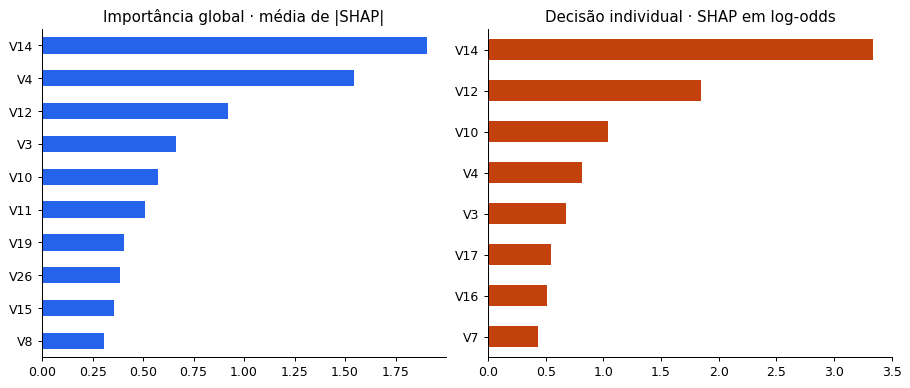

Classe real: 1. Escore: 0.999929. Limiar XGBoost: 0.488272.
Margem: 9.55595. Viés: 1.09638. Maior contribuição positiva: V14 (+3.3365). Maior contribuição negativa: V8 (-0.4294).


In [8]:
nome_xgb = "XGBoost ponderado"
booster = modelos[nome_xgb].get_booster()
amostra = X_teste.sample(n=min(1200, len(X_teste)), random_state=SEED)
valores_globais = booster.predict(xgb.DMatrix(amostra), pred_contribs=True)[:, :-1]
importancia = pd.Series(np.abs(valores_globais).mean(axis=0), index=X_teste.columns)
top_global = importancia.nlargest(10).sort_values()

scores_xgb = pd.Series(scores_teste[nome_xgb], index=X_teste.index)
limiar_xgb = limiares[nome_xgb][0]
fraudes_sinalizadas = scores_xgb[y_teste.eq(1) & scores_xgb.ge(limiar_xgb)]
indice = fraudes_sinalizadas.idxmax() if len(fraudes_sinalizadas) else scores_xgb.idxmax()
caso = xgb.DMatrix(X_teste.loc[[indice]])
contribuicoes = booster.predict(caso, pred_contribs=True)[0]
margem = float(booster.predict(caso, output_margin=True)[0])
np.testing.assert_allclose(contribuicoes.sum(), margem, rtol=1e-4, atol=1e-4)

shap_local = pd.Series(contribuicoes[:-1], index=X_teste.columns)
top_local = shap_local.loc[shap_local.abs().nlargest(8).index].sort_values()
fig, eixos = plt.subplots(1, 2, figsize=(10, 4.2), layout="constrained")
top_global.plot.barh(ax=eixos[0], color="#2563eb")
eixos[0].set_title("Importância global · média de |SHAP|")
top_local.plot.barh(ax=eixos[1], color=np.where(top_local >= 0, "#c2410c", "#0f766e"))
eixos[1].axvline(0, color="gray", linewidth=0.8)
eixos[1].set_title("Decisão individual · SHAP em log-odds")
plt.show()
print(f"Classe real: {y_teste.loc[indice]}. Escore: {scores_xgb.loc[indice]:.6f}. "
      f"Limiar XGBoost: {limiar_xgb:.6f}.")
print(f"Margem: {margem:.5f}. Viés: {contribuicoes[-1]:.5f}. "
      f"Maior contribuição positiva: {shap_local.idxmax()} ({shap_local.max():+.4f}). "
      f"Maior contribuição negativa: {shap_local.idxmin()} ({shap_local.min():+.4f}).")

## 7. Leitura dos resultados e limites

O resultado do teste é uma estimativa retrospectiva para a prevalência observada. A meta de precisão foi aplicada na validação. A precisão no teste pode ser diferente. O conjunto cobre apenas dois dias e tem poucas fraudes. Para uso operacional, é necessário validar em dados mais recentes e em ordem temporal, estudar custos de falsos alertas e monitorar mudanças na prevalência. O resultado orienta revisão, sem automatizar bloqueios reais.

In [9]:
r = teste.loc[modelo_escolhido]
print(f"{modelo_escolhido}: {int(r.VP)} fraudes sinalizadas, {int(r.FN)} fraudes perdidas "
      f"e {int(r.FP)} falsos alertas no teste.")
print(f"Precisão {r['precisão']:.2%} | recall {r.recall:.2%} | F1 {r.F1:.4f} | AP {r.AP:.4f}")

Random Forest ponderada: 77 fraudes sinalizadas, 18 fraudes perdidas e 22 falsos alertas no teste.
Precisão 77.78% | recall 81.05% | F1 0.7938 | AP 0.8424
